# RetentionInsight AI — EDA
**Auteur : Équipe Data Science**  
Objectif : Charger les données brutes, auditer leur qualité, et visualiser les distributions clés.

> Librairies utilisées : `pandas`, `numpy` pour la manipulation, `matplotlib` et `seaborn` pour la visualisation.

In [27]:
# stdlib
import warnings

# third-party — data
import numpy as np
import pandas as pd

# third-party — visualisation
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="darkgrid", palette="muted", font_scale=1.2)
plt.rcParams["figure.dpi"] = 120

DATA_PATH = "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
print("Imports OK.")

Imports OK.


## 1. Chargement des données

In [28]:
def load_raw_data(path: str) -> pd.DataFrame:
    """
    Charge le dataset Telco brut depuis un fichier CSV.

    Args:
        path (str): Chemin relatif ou absolu vers le fichier CSV.

    Returns:
        pd.DataFrame: DataFrame brut non modifié.

    Raises:
        AssertionError: Si la colonne 'customerID' est absente (fichier incorrect).
        FileNotFoundError: Si le chemin est invalide.
    """
    df_raw = pd.read_csv(path)

    # Validation défensive du schéma minimum attendu
    required_cols = ["customerID", "Churn", "TotalCharges", "MonthlyCharges", "Contract"]
    for col in required_cols:
        assert col in df_raw.columns, f"Colonne obligatoire absente : '{col}'"

    # Log mémoire initiale
    mem_mb = df_raw.memory_usage(deep=True).sum() / 1024**2
    print(f"[MEM] Mémoire occupée après chargement : {mem_mb:.2f} MB")
    print(f"[INFO] Shape : {df_raw.shape[0]} lignes × {df_raw.shape[1]} colonnes")

    return df_raw


df_raw = load_raw_data(DATA_PATH)
df_raw.head()

[MEM] Mémoire occupée après chargement : 7.79 MB
[INFO] Shape : 7043 lignes × 21 colonnes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Audit qualité des données

### 2.1 Types de données (dtypes)

In [29]:
def audit_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    """
    Génère un rapport des types de données par colonne.

    Args:
        df (pd.DataFrame): Dataset à auditer.

    Returns:
        pd.DataFrame: Tableau récapitulatif des dtypes et cardinalités.
    """
    report = pd.DataFrame({
        "dtype":       df.dtypes,
        "n_unique":    df.nunique(),
        "sample_val":  df.iloc[0],
    })
    return report


audit_dtypes(df_raw)

,dtype,n_unique,sample_val
customerID,object,7043,7590-VHVEG
gender,object,2,Female
SeniorCitizen,int64,2,0
Partner,object,2,Yes
Dependents,object,2,No
tenure,int64,73,1
PhoneService,object,2,No
MultipleLines,object,3,No phone service
InternetService,object,3,DSL
OnlineSecurity,object,3,No


### 2.2 Valeurs nulles & chaînes vides — détection complète

> **⚠️ Problème connu :** La colonne `TotalCharges` est chargée en `object` (str) au lieu de `float`.
> Cela est dû à des entrées qui contiennent une chaîne vide `" "` (espace) pour les nouveaux clients
> (tenure = 0) qui n'ont pas encore été facturés. Ces valeurs **ne sont pas détectées** par `isna()`
> et constituent des **NaN cachés**.

In [30]:
def audit_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """
    Audite les valeurs manquantes réelles (NaN) et les chaînes vides cachées.

    Args:
        df (pd.DataFrame): Dataset brut à auditer.

    Returns:
        pd.DataFrame: Rapport complet par colonne : NaN réels, chaînes vides, total manquant.

    Notes:
        - Les chaînes vides (" ") dans les colonnes object ne sont PAS capturées par isna().
        - Cette fonction les détecte explicitement via str.strip() == "".
    """
    # NaN strategy: détection en deux passes — NaN réels + chaînes vides
    nan_real = df.isna().sum()

    # Détection des chaînes vides dans les colonnes de type object uniquement
    empty_str = pd.Series(0, index=df.columns, dtype="int64")
    for col in df.select_dtypes(include="object").columns:
        empty_str[col] = (df[col].str.strip() == "").sum()

    report = pd.DataFrame({
        "nan_reels":     nan_real,
        "chaines_vides": empty_str,
        "total_manquant": nan_real + empty_str,
        "pct_manquant":  ((nan_real + empty_str) / len(df) * 100).round(2),
    })
    return report.sort_values("total_manquant", ascending=False)


rapport_missing = audit_missing_values(df_raw)
print("=" * 55)
print("AUDIT VALEURS MANQUANTES (NaN réels + chaînes vides)")
print("=" * 55)
rapport_missing

AUDIT VALEURS MANQUANTES (NaN réels + chaînes vides)


,nan_reels,chaines_vides,total_manquant,pct_manquant
TotalCharges,0,11,11,0.16
customerID,0,0,0,0.00
DeviceProtection,0,0,0,0.00
MonthlyCharges,0,0,0,0.00
PaymentMethod,0,0,0,0.00
PaperlessBilling,0,0,0,0.00
Contract,0,0,0,0.00
StreamingMovies,0,0,0,0.00
StreamingTV,0,0,0,0.00
TechSupport,0,0,0,0.00


In [31]:
# Focus sur TotalCharges : mise en évidence du problème
n_empty_tc = (df_raw["TotalCharges"].str.strip() == "").sum()
print(f"[⚠️  TotalCharges] dtype actuel       : {df_raw['TotalCharges'].dtype}")
print(f"[⚠️  TotalCharges] NaN détectés par isna() : {df_raw['TotalCharges'].isna().sum()}")
print(f"[⚠️  TotalCharges] Chaînes vides ' '  : {n_empty_tc}  <-- NaN CACHÉS")
print()

# Affichage des lignes concernées
mask_empty = df_raw["TotalCharges"].str.strip() == ""
print("Lignes avec TotalCharges vide :")
df_raw.loc[mask_empty, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

[⚠️  TotalCharges] dtype actuel       : object
[⚠️  TotalCharges] NaN détectés par isna() : 0
[⚠️  TotalCharges] Chaînes vides ' '  : 11  <-- NaN CACHÉS

Lignes avec TotalCharges vide :


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Conclusion audit :** Les 11 lignes avec `TotalCharges == " "` correspondent toutes à des clients
avec `tenure == 0` (nouveaux abonnés). Ce problème sera traité dans `2_cleaning.py`
avec la stratégie : **imputation par `MonthlyCharges * tenure`** (= 0), puis conversion en `float32`.

## 3. Visualisations exploratoires

### 3.1 Distribution de la variable cible : `Churn`

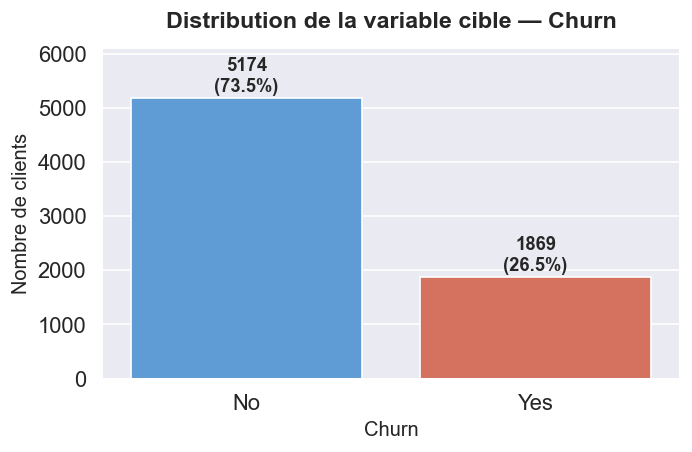

Déséquilibre de classes : ratio No/Yes = 73.5% / 26.5%
→ Dataset déséquilibré : utiliser class_weight='balanced' lors de la modélisation.


In [32]:
# Validation préalable
assert "Churn" in df_raw.columns, "Colonne 'Churn' manquante."

churn_counts = df_raw["Churn"].value_counts()
churn_pct    = df_raw["Churn"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))

bars = sns.countplot(
    data=df_raw,
    x="Churn",
    order=["No", "Yes"],
    palette=["#4C9BE8", "#E8634C"],
    ax=ax,
)

# Annotations des pourcentages sur les barres
for i, (label, count) in enumerate(zip(["No", "Yes"], churn_counts[["No", "Yes"]])):
    pct = churn_pct[label]
    ax.text(i, count + 50, f"{count}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=11, fontweight="bold")

ax.set_title("Distribution de la variable cible — Churn", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Churn", fontsize=12)
ax.set_ylabel("Nombre de clients", fontsize=12)
ax.set_ylim(0, churn_counts.max() * 1.18)
plt.tight_layout()
plt.show()

print(f"Déséquilibre de classes : ratio No/Yes = {churn_pct['No']:.1f}% / {churn_pct['Yes']:.1f}%")
print("→ Dataset déséquilibré : utiliser class_weight='balanced' lors de la modélisation.")

### 3.2 Churn par type de contrat : `Contract`

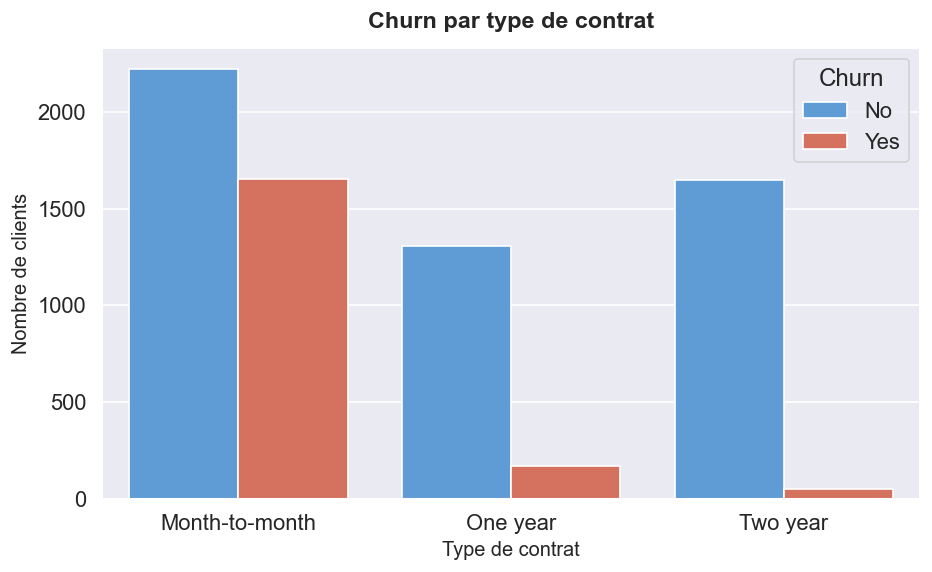

Taux de churn par type de contrat :
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8


In [33]:
# Validation préalable
assert "Contract" in df_raw.columns, "Colonne 'Contract' manquante."

contract_order = ["Month-to-month", "One year", "Two year"]

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=df_raw,
    x="Contract",
    hue="Churn",
    order=contract_order,
    hue_order=["No", "Yes"],
    palette={"No": "#4C9BE8", "Yes": "#E8634C"},
    ax=ax,
)

ax.set_title("Churn par type de contrat", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Type de contrat", fontsize=12)
ax.set_ylabel("Nombre de clients", fontsize=12)
ax.legend(title="Churn", frameon=True)
plt.tight_layout()
plt.show()

# Calcul du taux de churn par contrat
churn_by_contract = (
    df_raw.groupby("Contract")["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("pct")
    .reset_index()
    .query("Churn == 'Yes'")
    .set_index("Contract")["pct"]
    .round(1)
)
print("Taux de churn par type de contrat :")
print(churn_by_contract.to_string())

### 3.3 Distribution de `MonthlyCharges` par `Churn`

[NaN check] MonthlyCharges — NaN détectés : 0


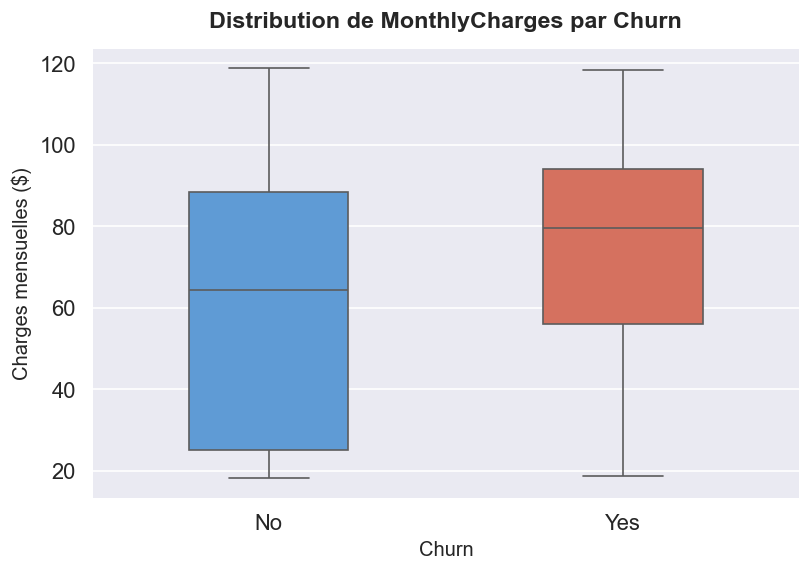


Stats descriptives MonthlyCharges par Churn :


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


In [34]:
# Validation préalable
assert "MonthlyCharges" in df_raw.columns, "Colonne 'MonthlyCharges' manquante."
assert pd.api.types.is_numeric_dtype(df_raw["MonthlyCharges"]), \
    "MonthlyCharges n'est pas numérique — vérifier le chargement."

# NaN strategy: vérification avant boxplot
n_nan_mc = df_raw["MonthlyCharges"].isna().sum()
print(f"[NaN check] MonthlyCharges — NaN détectés : {n_nan_mc}")

fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=df_raw,
    x="Churn",
    y="MonthlyCharges",
    order=["No", "Yes"],
    palette={"No": "#4C9BE8", "Yes": "#E8634C"},
    width=0.45,
    flierprops=dict(marker="o", markerfacecolor="grey", markersize=3, alpha=0.5),
    ax=ax,
)

ax.set_title("Distribution de MonthlyCharges par Churn", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Churn", fontsize=12)
ax.set_ylabel("Charges mensuelles ($)", fontsize=12)
plt.tight_layout()
plt.show()

# Stats descriptives
print("\nStats descriptives MonthlyCharges par Churn :")
df_raw.groupby("Churn")["MonthlyCharges"].describe().round(2)

## 4. Statistiques descriptives

In [35]:
# Statistiques descriptives des variables numériques
print("[STATS] Statistiques descriptives — variables numériques")
numeric_desc = df_raw.select_dtypes(include=["number"]).describe().T
numeric_desc["median"] = df_raw.select_dtypes(include=["number"]).median()
numeric_desc = numeric_desc[["count","mean","median","std","min","25%","75%","max"]]
display(numeric_desc.style.format("{:.2f}").set_caption("Statistiques descriptives — Variables numériques"))

[STATS] Statistiques descriptives — variables numériques


,count,mean,median,std,min,25%,75%,max
SeniorCitizen,7043.00,0.16,0.00,0.37,0.00,0.00,0.00,1.00
tenure,7043.00,32.37,29.00,24.56,0.00,9.00,55.00,72.00
MonthlyCharges,7043.00,64.76,70.35,30.09,18.25,35.50,89.85,118.75


### 4.1 Taux de churn par ancienneté (tenure buckétisée)

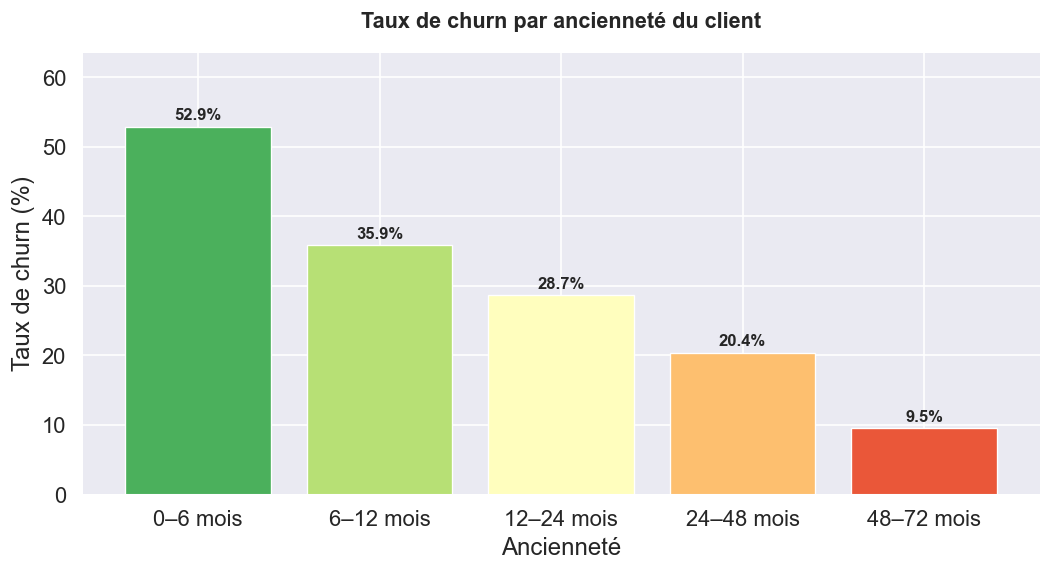

tenure_bucket  Taux de churn (%)
     0–6 mois          52.937205
    6–12 mois          35.886525
   12–24 mois          28.710938
   24–48 mois          20.388959
   48–72 mois           9.513176


In [36]:
assert "tenure" in df_raw.columns
assert pd.api.types.is_numeric_dtype(df_raw["tenure"])

df_plot = df_raw.copy()
df_plot["tenure_bucket"] = pd.cut(
    df_plot["tenure"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=["0–6 mois", "6–12 mois", "12–24 mois", "24–48 mois", "48–72 mois"],
    include_lowest=True,
)
churn_by_tenure = (
    df_plot.groupby("tenure_bucket", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index()
    .rename(columns={"Churn": "Taux de churn (%)"})
)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
    churn_by_tenure["tenure_bucket"].astype(str),
    churn_by_tenure["Taux de churn (%)"],
    color=sns.color_palette("RdYlGn_r", len(churn_by_tenure)),
    edgecolor="white", linewidth=0.8,
)
for bar, val in zip(bars, churn_by_tenure["Taux de churn (%)"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{val:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("Taux de churn par ancienneté du client", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Ancienneté")
ax.set_ylabel("Taux de churn (%)")
ax.set_ylim(0, churn_by_tenure["Taux de churn (%)"].max() * 1.2)
sns.despine()
plt.tight_layout()
plt.show()
print(churn_by_tenure.to_string(index=False))

### 4.2 Distribution de l'ancienneté (tenure) — Churn vs. Non-Churn

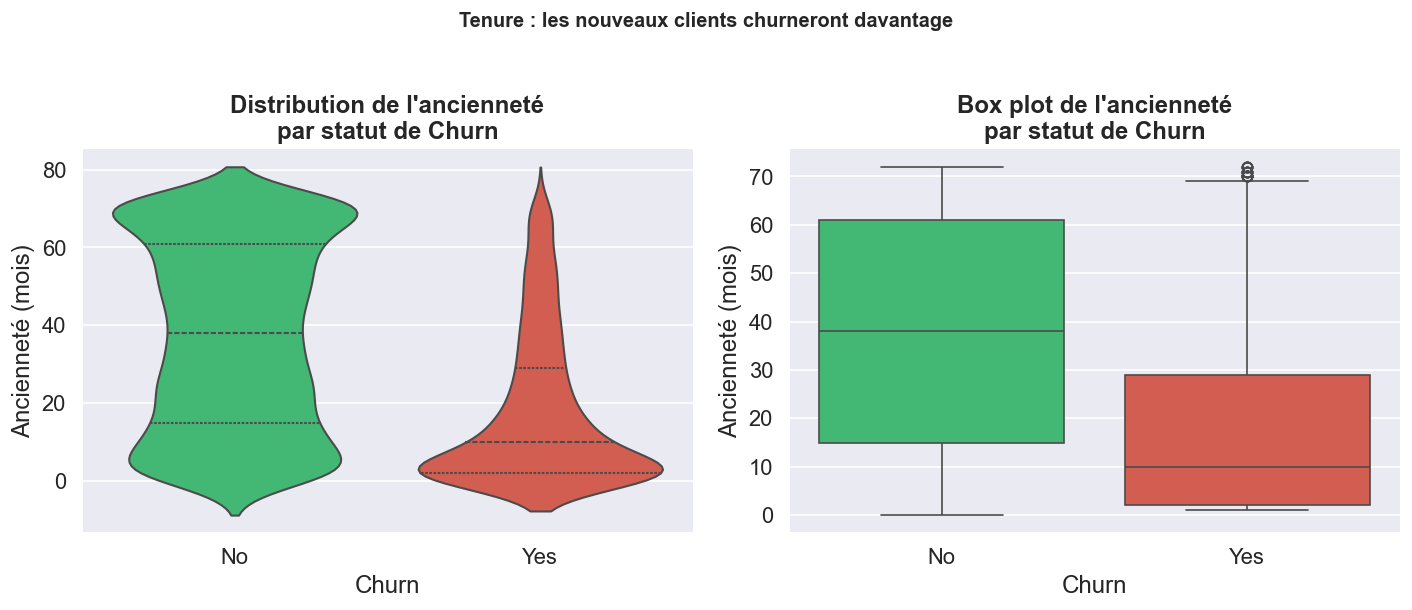

Churn=No → médiane=38 mois, moyenne=37.6 mois
Churn=Yes → médiane=10 mois, moyenne=18.0 mois


In [37]:
assert "tenure" in df_raw.columns
assert "Churn" in df_raw.columns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Violin plot
sns.violinplot(
    data=df_raw, x="Churn", y="tenure",
    palette={"No": "#2ecc71", "Yes": "#e74c3c"},
    inner="quartile", ax=axes[0]
)
axes[0].set_title("Distribution de l'ancienneté\npar statut de Churn", fontweight="bold")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Ancienneté (mois)")
# Box plot
sns.boxplot(
    data=df_raw, x="Churn", y="tenure",
    palette={"No": "#2ecc71", "Yes": "#e74c3c"},
    ax=axes[1]
)
axes[1].set_title("Box plot de l'ancienneté\npar statut de Churn", fontweight="bold")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Ancienneté (mois)")
sns.despine()
plt.suptitle("Tenure : les nouveaux clients churneront davantage",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()
for grp, sub in df_raw.groupby("Churn")["tenure"]:
    print(f"Churn={grp} → médiane={sub.median():.0f} mois, moyenne={sub.mean():.1f} mois")

### 4.3 Churn par méthode de paiement

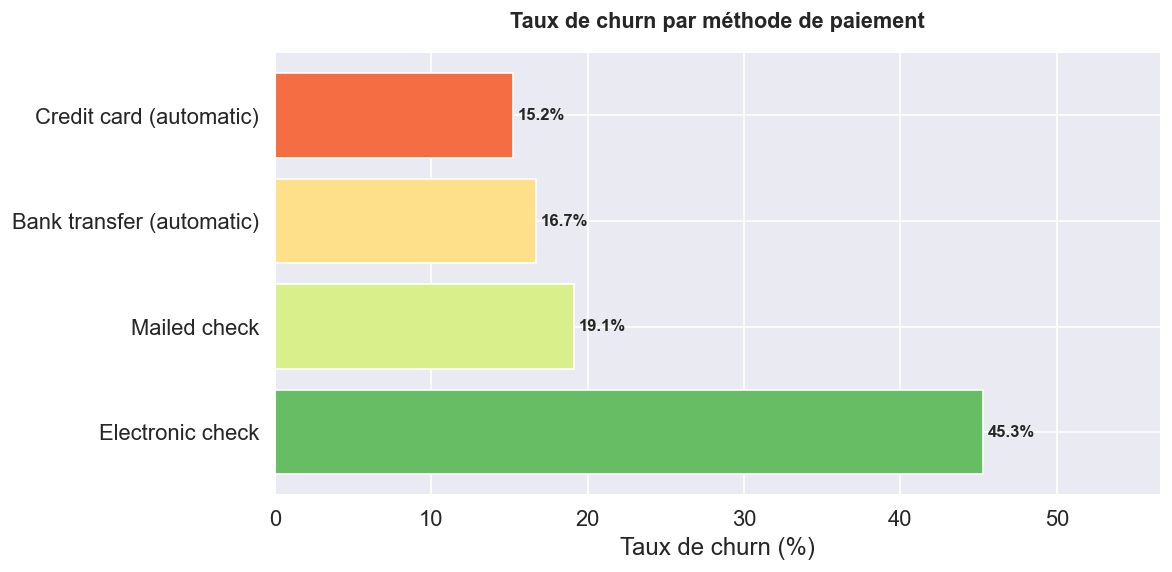

            PaymentMethod  Taux de churn (%)
         Electronic check          45.285412
             Mailed check          19.106700
Bank transfer (automatic)          16.709845
  Credit card (automatic)          15.243101


In [38]:
assert "PaymentMethod" in df_raw.columns
assert "Churn" in df_raw.columns

churn_by_payment = (
    df_raw.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={"Churn": "Taux de churn (%)"})
)
fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette("RdYlGn_r", len(churn_by_payment))
bars = ax.barh(
    churn_by_payment["PaymentMethod"],
    churn_by_payment["Taux de churn (%)"],
    color=colors, edgecolor="white"
)
for bar, val in zip(bars, churn_by_payment["Taux de churn (%)"]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f"{val:.1f}%", va="center", fontsize=10, fontweight="bold")
ax.set_title("Taux de churn par méthode de paiement", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Taux de churn (%)")
ax.set_xlim(0, churn_by_payment["Taux de churn (%)"].max() * 1.25)
sns.despine()
plt.tight_layout()
plt.show()
print(churn_by_payment.to_string(index=False))

### 4.4 Matrice de corrélation — Variables numériques

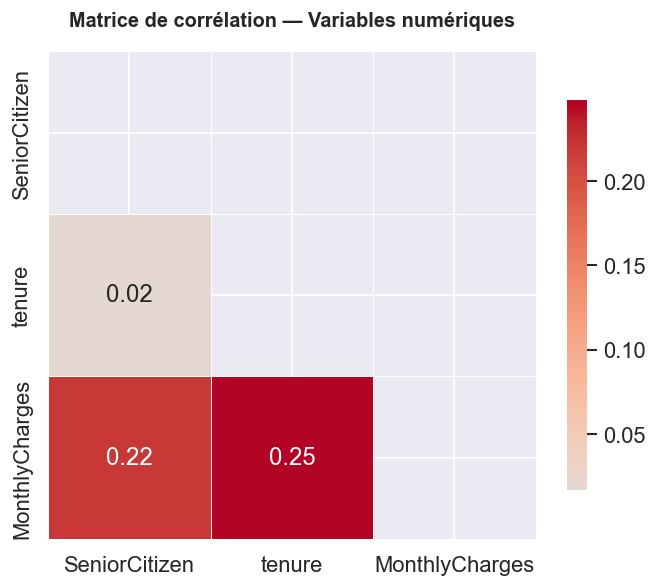

[STATS] Corrélations avec TotalCharges :


KeyError: 'TotalCharges'

In [39]:
import warnings
numeric_cols = df_raw.select_dtypes(include=["number"]).columns.tolist()
corr_matrix = df_raw[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    ax=ax,
    square=True,
    cbar_kws={"shrink": 0.8}
)
ax.set_title("Matrice de corrélation — Variables numériques",
             fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()
print("[STATS] Corrélations avec TotalCharges :")
print(corr_matrix["TotalCharges"].drop("TotalCharges").sort_values(ascending=False))